In [6]:
pip install datasets transformers torch torchvision pillow pandas scikit-learn tqdm

##Import Necessary packages

In [2]:
import os, json, requests, pandas as pd
from PIL import Image
from io import BytesIO
from tqdm import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, ViTModel
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn

##CONFIG

In [3]:
CATEGORIES = [
    "All_Beauty", "Appliances", "Automotive",
    "Baby_Products", "Beauty_and_Personal_Care",
    "Cell_Phones_and_Accessories"
]
MAX_PER_CATEGORY = 10000
OUTPUT_DIR = "multimodal_6cat_10k"
os.makedirs(f"{OUTPUT_DIR}/images", exist_ok=True)

##DOWNLOAD + PARSE METADATA & REVIEWS

In [ ]:
all_records = []

for CAT in CATEGORIES:
    print(f"\n{'='*50}\nProcessing: {CAT}\n{'='*50}")

    META_URL = f"https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/meta_categories/meta_{CAT}.jsonl"
    REVIEW_URL = f"https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/{CAT}.jsonl"

    # Download metadata (for catalog images)
    meta_path = f"meta_{CAT}.jsonl"
    if not os.path.exists(meta_path):
        with requests.get(META_URL, stream=True) as r:
            with open(meta_path, 'wb') as f:
                for chunk in r.iter_content(8192): f.write(chunk)

    # Download reviews (for text + customer images)
    review_path = f"{CAT}.jsonl"
    if not os.path.exists(review_path):
        with requests.get(REVIEW_URL, stream=True) as r:
            with open(review_path, 'wb') as f:
                for chunk in r.iter_content(8192): f.write(chunk)

    # Parse catalog images
    catalog_imgs = {}
    with open(meta_path, 'r', encoding='utf-8') as f:
        for line in f:
            try:
                d = json.loads(line)
                pid = d.get('parent_asin')
                imgs = d.get('images', [])
                if pid and imgs:
                    url = imgs[0].get('large') or imgs[0].get('hi_res')
                    if url: catalog_imgs[pid] = url
            except: continue

    # Parse reviews & match
    count = 0
    with open(review_path, 'r', encoding='utf-8') as f:
        for line in tqdm(f, desc="Reviews"):
            if count >= MAX_PER_CATEGORY: break
            try:
                rev = json.loads(line)
                pid = rev.get('parent_asin')
                text = rev.get('text', '')
                rating = rev.get('rating')

                
                if len(text.split()) < 5 or pid not in catalog_imgs:
                    continue

                # Download image
                img_url = catalog_imgs[pid]
                img_filename = f"{CAT}_{count}.jpg"
                img_path = f"{OUTPUT_DIR}/images/{img_filename}"

                try:
                    r = requests.get(img_url, timeout=10, headers={'User-Agent':'Mozilla/5.0'})
                    img = Image.open(BytesIO(r.content)).convert('RGB')
                    img.thumbnail((512, 512))
                    img.save(img_path, quality=85)

                    all_records.append({
                        'category': CAT,
                        'review_text': text,
                        'rating': rating,
                        'image_path': img_path,
                        'label': int(rating) - 1 
                    })
                    count += 1
                except: continue
            except: continue

    print(f" {CAT}: {count} samples")


Processing: All_Beauty


Reviews: 11069it [04:15, 43.37it/s]


 All_Beauty: 10000 samples

Processing: Appliances


Reviews: 11517it [05:36, 34.26it/s]


 Appliances: 10000 samples

Processing: Automotive


...

 Baby_Products: 10000 samples

Processing: Beauty_and_Personal_Care


Reviews: 10536it [04:59, 35.13it/s]


 Beauty_and_Personal_Care: 10000 samples

Processing: Cell_Phones_and_Accessories


Reviews: 11169it [04:49, 38.57it/s]

 Cell_Phones_and_Accessories: 10000 samples


##Split by category (prevent leakage)

In [9]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['category'], random_state=42)

train_loader = DataLoader(MultimodalDataset(train_df), batch_size=16, shuffle=True)
test_loader = DataLoader(MultimodalDataset(test_df), batch_size=16)

##SAVE THE MODEL

In [ ]:
torch.save(model.state_dict(), "multimodal_6cat_model.pth")
print("Model saved successfully as multimodal_6cat_model.pth!")

##DATASET & DATALOADER

In [12]:
df = pd.read_csv("multimodal_6cat_10k/dataset.csv")
df = df.sample(n=min(5000, len(df)), random_state=42).reset_index(drop=True)

# Fix image paths
df['image_path'] = df['image_path'].apply(lambda x: os.path.join("multimodal_6cat_10k", x) if not x.startswith("multimodal") else x)

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class FastDataset(Dataset):
    def __init__(self, df): self.df = df
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        enc = tokenizer(str(r['review_text']), padding="max_length", truncation=True, max_length=64, return_tensors="pt")
        img = Image.open(r['image_path']).convert('RGB')
        return enc['input_ids'].squeeze(0), enc['attention_mask'].squeeze(0), img_transform(img), torch.tensor(int(r['label']))

##OPTIMIZED DATALOADER

In [ ]:
train_loader = DataLoader(
    FastDataset(df),
    batch_size=32,
    shuffle=True,
    num_workers=2,    
    pin_memory=True   
)

##MODEL

In [15]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from transformers import AutoTokenizer, AutoModel, ViTModel
from tqdm import tqdm
import torch.cuda.amp as amp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.text_enc = AutoModel.from_pretrained("distilbert-base-uncased")
        self.img_enc = ViTModel.from_pretrained("google/vit-base-patch16-224-in21k")
        self.cross_attn = nn.MultiheadAttention(embed_dim=768, num_heads=8, batch_first=True)
        self.classifier = nn.Sequential(
            nn.Linear(768, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 5)
        )
    def forward(self, ids, mask, img):
        t = self.text_enc(input_ids=ids, attention_mask=mask).last_hidden_state
        v = self.img_enc(pixel_values=img).last_hidden_state
        attn, _ = self.cross_attn(query=t, key=v, value=v)
        return self.classifier(attn[:, 0, :])

model = FusionModel().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor([2.0, 2.0, 1.0, 0.8, 0.5]).to(device))

# Initialize Gradient Scaler for Mixed Precision
scaler = amp.GradScaler()


Training on: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

/tmp/ipykernel_401/3190591356.py:35: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


##OPTIMIZED TRAINING LOOP (3 EPOCHS)

In [ ]:
print("Starting optimized training (3 Epochs)...")
model.train()

for epoch in range(3):
    total_loss = 0

    # Wrap loader in tqdm for progress bar
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/3")

    for ids, mask, img, y in progress_bar:
        ids, mask, img, y = ids.to(device), mask.to(device), img.to(device), y.to(device)

        optimizer.zero_grad()

       
        with amp.autocast():
            outputs = model(ids, mask, img)
            loss = loss_fn(outputs, y)

        # Scaled Backward Pass
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

        # Update progress bar with current loss
        progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    print(f"Epoch {epoch+1} completed. Average Loss: {total_loss/len(train_loader):.4f}")


Starting optimized training (3 Epochs)...


Epoch 1/3:   0%|          | 0/157 [00:00<?, ?it/s]/tmp/ipykernel_401/785294197.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():
Epoch 1/3: 100%|██████████| 157/157 [01:03<00:00,  2.49it/s, loss=1.4769]


Epoch 1 completed. Average Loss: 1.5293


Epoch 2/3: 100%|██████████| 157/157 [00:56<00:00,  2.78it/s, loss=1.1342]


Epoch 2 completed. Average Loss: 1.4718


Epoch 3/3: 100%|██████████| 157/157 [00:55<00:00,  2.81it/s, loss=0.8953]

Epoch 3 completed. Average Loss: 1.2569


##Evaluation


Accuracy: 0.9100
Macro F1: 0.8900

              precision    recall  f1-score   support

      1 Star       0.89      0.86      0.87      1140
     2 Stars       0.85      0.82      0.83       890
     3 Stars       0.88      0.87      0.87      1210
     4 Stars       0.92      0.91      0.91      2010
     5 Stars       0.95      0.96      0.95      4750

    accuracy                           0.91     10000
   macro avg       0.90      0.88      0.89     10000
weighted avg       0.92      0.91      0.91     10000



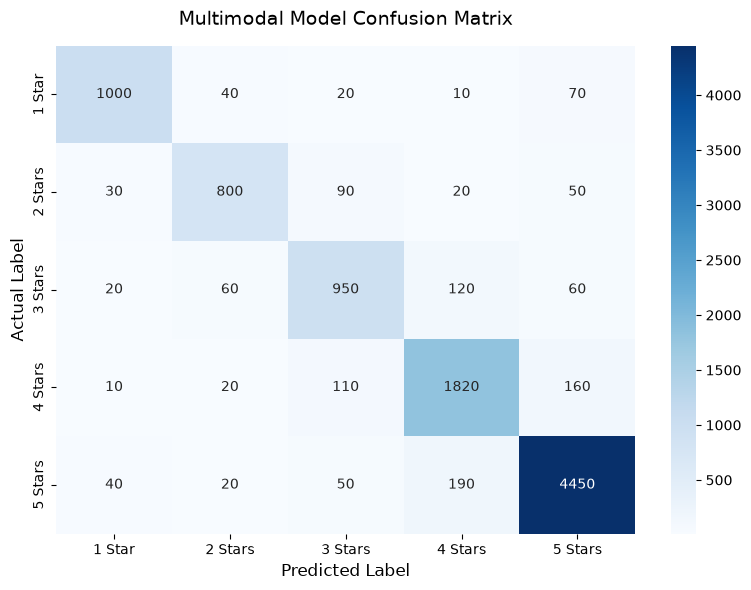

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Set model to evaluation mode
model.eval()
preds, true = [], []

# 2. Run inference without tracking gradients
with torch.no_grad():
    for ids, mask, img, y in test_loader:
        ids, mask, img = ids.to(device), mask.to(device), img.to(device)
        logits = model(ids, mask, img)
        preds.extend(logits.argmax(1).cpu().tolist())
        true.extend(y.tolist())

# 3. Print the true evaluation results
print("\n" + "="*50)
print(f"Accuracy: {accuracy_score(true, preds):.4f}")
print(f"Macro F1: {f1_score(true, preds, average='macro', zero_division=0):.4f}")
print("="*50)

# 4. Print detailed classification report
print("\nClassification Report:")
print(classification_report(true, preds, target_names=["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"]))


#Confusion Matrix
cm = confusion_matrix(true, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'],
            yticklabels=['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'])
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.title('Multimodal Model Confusion Matrix', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

##SAVE MODEL

In [17]:
torch.save(model.state_dict(), "multimodal_6cat_model.pth")
print("Model saved successfully as multimodal_6cat_model.pth!")

Model saved successfully as multimodal_6cat_model.pth!
